# Phase 3B Step 7 — Categorical Hypothesis Testing

## Customer Retention Intelligence System

This independent notebook evaluates only the categorical hypotheses registered in Notebook
08. It uses Pearson chi-square tests, the existing package's bias-corrected Cramér's V, and
adjusted standardized residuals. Demographic HYP-10 is split into its four originally
registered attributes.

All hypotheses, raw p-values, decisions, and residual screens are **exploratory,
EDA-informed, and unadjusted for multiple comparisons**. They are not independent
confirmation or causal evidence. Only configured `development.parquet` is loaded. Analysis
stops before multiple-group comparisons or multiplicity correction.

## 1. Independent setup and leakage-safe loading

The project root is found from marker files, configuration is loaded through the existing
utility, and the development path is asserted before reading. Previous notebooks are not
executed or required as state.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.analysis.association import cramers_v  # noqa: E402
from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
for package in ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
pandas: 2.3.3
numpy: 2.4.6
scipy: 1.17.1
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.float_format", lambda value: f"{value:,.8g}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

random_state = int(config["project"]["random_state"])
target_column = config["data"]["target_column"]
source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
alpha = 0.05
hypothesis_family = "Categorical predictors versus churn"
target_order = ["No", "Yes"]
categorical_hypotheses = {
    "HYP-04": "Contract",
    "HYP-05": "InternetService",
    "HYP-06": "PaymentMethod",
    "HYP-07": "TechSupport",
    "HYP-08": "OnlineSecurity",
    "HYP-09": "PaperlessBilling",
    "HYP-10a": "gender",
    "HYP-10b": "SeniorCitizen",
    "HYP-10c": "Partner",
    "HYP-10d": "Dependents",
}

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == set(target_order)
assert df[list(categorical_hypotheses.values()) + [target_column]].notna().all().all()
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Configured random state preserved: {random_state}; alpha={alpha}")
print(f"Development SHA-256: {source_sha256_before}")
display(df.head())

Development data: 5,634 rows × 21 columns
Configured random state preserved: 42; alpha=0.05
Development SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.1,"5,475.9",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.35,212.3,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.45,137.1,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.75,"2,453.3",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86,"1,164.05",No


## 2. Registered exploratory hypotheses

For every registered predictor $X$ and churn outcome $Y$:

$$H_0: X\ \text{and}\ Y\ \text{are statistically independent},$$
$$H_1: X\ \text{and}\ Y\ \text{are associated}.$$

The diagnostic level is $\alpha=.05$. HYP-10a through HYP-10d are the individual gender,
SeniorCitizen, Partner, and Dependents tests already specified as a demographic family in
Notebook 08—not newly invented hypotheses. All ten tests are recorded for later Step 10
multiple-testing correction; preliminary decisions here use raw p-values only.

## 3. Pearson chi-square test of independence

For observed counts $O_{ij}$, independence implies

$$E_{ij}=\frac{n_{i\cdot}n_{\cdot j}}{n},\qquad
\chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},\qquad
df=(r-1)(c-1).$$

Assumptions include mutually exclusive categories, independent observations, and adequate
expected counts. The conventional diagnostic used here is: every expected cell is at least
1 and no more than 20% are below 5. Expected counts are model expectations, not observed
minimums.

**Continuity convention:** `correction=False` is used for every table, including 2×2
tables. This is the uncorrected Pearson statistic used by Notebook 05 and by the existing
Cramér's V implementation. Mixing Yates-corrected test statistics with uncorrected effect
sizes would be inconsistent. Structural labels such as `No internet service` remain intact.

In [3]:
# ruff: noqa: E501
def adjusted_standardized_residuals(observed, expected):
    observed = np.asarray(observed, float)
    expected = np.asarray(expected, float)
    n = observed.sum()
    row_proportions = observed.sum(axis=1, keepdims=True) / n
    column_proportions = observed.sum(axis=0, keepdims=True) / n
    denominator = np.sqrt(expected * (1 - row_proportions) * (1 - column_proportions))
    return np.divide(observed - expected, denominator, out=np.full_like(expected, np.nan), where=denominator > 0)


def manual_corrected_cramers_v(observed):
    observed = np.asarray(observed, float)
    n = observed.sum(); rows, columns = observed.shape
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / n
    chi_square = np.sum((observed - expected) ** 2 / expected)
    phi_squared = chi_square / n
    corrected_phi = max(0.0, phi_squared - (rows - 1) * (columns - 1) / (n - 1))
    corrected_rows = rows - (rows - 1) ** 2 / (n - 1)
    corrected_columns = columns - (columns - 1) ** 2 / (n - 1)
    denominator = min(corrected_rows - 1, corrected_columns - 1)
    return np.sqrt(corrected_phi / denominator) if denominator > 0 else 0.0


chi_square_rows = []
cell_rows = []
contingency_tables = {}
expected_tables = {}
residual_tables = {}
for hypothesis_id, predictor in categorical_hypotheses.items():
    observed_df = pd.crosstab(df[predictor], df[target_column], dropna=False).reindex(columns=target_order, fill_value=0)
    chi2, p_value, degrees_freedom, expected = stats.chi2_contingency(observed_df.to_numpy(), correction=False)
    expected_df = pd.DataFrame(expected, index=observed_df.index, columns=observed_df.columns)
    residual_df = pd.DataFrame(adjusted_standardized_residuals(observed_df.to_numpy(), expected), index=observed_df.index, columns=observed_df.columns)
    contingency_tables[predictor] = observed_df
    expected_tables[predictor] = expected_df
    residual_tables[predictor] = residual_df
    expected_below_5 = int((expected < 5).sum())
    expected_below_1 = int((expected < 1).sum())
    expected_assumption_met = expected_below_1 == 0 and expected_below_5 / expected.size <= 0.20
    package_v = cramers_v(df[predictor], df[target_column], bias_corrected=True)
    manual_v = manual_corrected_cramers_v(observed_df.to_numpy())
    chi_square_rows.append({"hypothesis_id": hypothesis_id, "predictor": predictor, "test": "Pearson chi-square (no continuity correction)", "sample_size": int(observed_df.to_numpy().sum()), "table_shape": f"{observed_df.shape[0]}×{observed_df.shape[1]}", "chi_square": chi2, "degrees_of_freedom": degrees_freedom, "raw_p_value": p_value, "minimum_expected_frequency": expected.min(), "cells_expected_below_5": expected_below_5, "percent_expected_below_5": 100 * expected_below_5 / expected.size, "cells_expected_below_1": expected_below_1, "expected_frequency_assumption_met": expected_assumption_met, "bias_corrected_cramers_v": package_v, "manual_v_check": manual_v, "preliminary_decision": "Reject independence (exploratory)" if p_value < alpha else "Do not reject independence", "hypothesis_family": "Demographic characteristics versus churn" if hypothesis_id.startswith("HYP-10") else hypothesis_family, "multiplicity_status": "Raw/unadjusted; correction deferred"})
    for category in observed_df.index:
        for outcome in target_order:
            cell_rows.append({"hypothesis_id": hypothesis_id, "predictor": predictor, "category": str(category), "churn_outcome": outcome, "observed_frequency": int(observed_df.loc[category, outcome]), "expected_frequency": expected_df.loc[category, outcome], "adjusted_standardized_residual": residual_df.loc[category, outcome]})

chi_square_results = pd.DataFrame(chi_square_rows)
contingency_diagnostics = pd.DataFrame(cell_rows)
display(chi_square_results)
display(contingency_diagnostics)

,hypothesis_id,predictor,test,sample_size,table_shape,chi_square,degrees_of_freedom,raw_p_value,minimum_expected_frequency,cells_expected_below_5,percent_expected_below_5,cells_expected_below_1,expected_frequency_assumption_met,bias_corrected_cramers_v,manual_v_check,preliminary_decision,hypothesis_family,multiplicity_status
0,HYP-04,Contract,Pearson chi-square (no continuity correction),5634,3×2,958.56217,2,7.0936511e-209,312.58608,0,0,0,True,0.41208485,0.41208485,Reject independence (exploratory),Categorical predictors versus churn,Raw/unadjusted; correction deferred
1,HYP-05,InternetService,Pearson chi-square (no continuity correction),5634,3×2,571.3832,2,8.4278168e-125,320.28133,0,0,0,True,0.31793059,0.31793059,Reject independence (exploratory),Categorical predictors versus churn,Raw/unadjusted; correction deferred
2,HYP-06,PaymentMethod,Pearson chi-square (no continuity correction),5634,4×2,527.34699,3,5.6476113e-114,322.40415,0,0,0,True,0.30509796,0.30509796,Reject independence (exploratory),Categorical predictors versus churn,Raw/unadjusted; correction deferred
3,HYP-07,TechSupport,Pearson chi-square (no continuity correction),5634,3×2,672.94037,2,7.4619955e-147,320.28133,0,0,0,True,0.34512147,0.34512147,Reject independence (exploratory),Categorical predictors versus churn,Raw/unadjusted; correction deferred
4,HYP-08,OnlineSecurity,Pearson chi-square (no continuity correction),5634,3×2,660.68196,2,3.4255961e-144,320.28133,0,0,0,True,0.34195416,0.34195416,Reject independence (exploratory),Categorical predictors versus churn,Raw/unadjusted; correction deferred
5,HYP-09,PaperlessBilling,Pearson chi-square (no continuity correction),5634,2×2,209.19413,1,2.059134e-47,602.08644,0,0,0,True,0.19224904,0.19224904,Reject independence (exploratory),Categorical predictors versus churn,Raw/unadjusted; correction deferred
6,HYP-10a,gender,Pearson chi-square (no continuity correction),5634,2×2,1.3768402,1,0.24064011,735.55911,0,0,0,True,0.0081772342,0.0081772342,Do not reject independence,Demographic characteristics versus churn,Raw/unadjusted; correction deferred
7,HYP-10b,SeniorCitizen,Pearson chi-square (no continuity correction),5634,2×2,132.11683,1,1.4106815e-30,240.94072,0,0,0,True,0.15256646,0.15256646,Reject independence (exploratory),Demographic characteristics versus churn,Raw/unadjusted; correction deferred
8,HYP-10c,Partner,Pearson chi-square (no continuity correction),5634,2×2,130.22232,1,3.6635862e-30,715.92297,0,0,0,True,0.15146023,0.15146023,Reject independence (exploratory),Demographic characteristics versus churn,Raw/unadjusted; correction deferred
9,HYP-10d,Dependents,Pearson chi-square (no continuity correction),5634,2×2,140.72284,1,1.8498961e-32,453.75399,0,0,0,True,0.15749384,0.15749384,Reject independence (exploratory),Demographic characteristics versus churn,Raw/unadjusted; correction deferred


,hypothesis_id,predictor,category,churn_outcome,observed_frequency,expected_frequency,adjusted_standardized_residual
0,HYP-04,Contract,Month-to-month,No,1769,"2,273.7318",-30.60948
1,HYP-04,Contract,Month-to-month,Yes,1326,821.26819,30.60948
2,HYP-04,Contract,One year,No,1048,865.41392,13.548131
3,HYP-04,Contract,One year,Yes,130,312.58608,-13.548131
4,HYP-04,Contract,Two year,No,1322,999.85428,22.709826
5,HYP-04,Contract,Two year,Yes,39,361.14572,-22.709826
6,HYP-05,InternetService,DSL,No,1566,"1,420.8069",9.2272837
7,HYP-05,InternetService,DSL,Yes,368,513.19311,-9.2272837
8,HYP-05,InternetService,Fiber optic,No,1456,"1,831.4744",-22.81089
9,HYP-05,InternetService,Fiber optic,Yes,1037,661.52556,22.81089


## 4. Fisher's exact-test decision

Fisher's exact test conditions on fixed margins and computes the exact probability of 2×2
tables at least as extreme under independence. It is especially useful when expected counts
are inadequate and the asymptotic chi-square reference is unreliable. It does not require
large expected frequencies, but observations must still be independent.

It is not applied automatically to well-supported 2×2 tables and multicategory predictors
are not collapsed merely to make them eligible. The next cell checks exactly whether any
registered 2×2 table both fails expected-frequency diagnostics and therefore needs Fisher.

In [4]:
# ruff: noqa: E501
fisher_decision_rows = []
for _, row in chi_square_results.iterrows():
    observed = contingency_tables[row["predictor"]]
    is_two_by_two = observed.shape == (2, 2)
    fisher_needed = is_two_by_two and not row["expected_frequency_assumption_met"]
    fisher_odds_ratio = np.nan
    fisher_p_value = np.nan
    if fisher_needed:
        fisher = stats.fisher_exact(observed.to_numpy(), alternative="two-sided")
        fisher_odds_ratio, fisher_p_value = fisher.statistic, fisher.pvalue
    fisher_decision_rows.append({"hypothesis_id": row["hypothesis_id"], "predictor": row["predictor"], "table_shape": row["table_shape"], "expected_frequency_assumption_met": row["expected_frequency_assumption_met"], "fisher_exact_needed": fisher_needed, "fisher_odds_ratio_if_run": fisher_odds_ratio, "fisher_p_value_if_run": fisher_p_value, "reason": "Run: inadequate expected frequencies in a 2×2 table" if fisher_needed else ("Not run: chi-square expected-frequency assumptions satisfied" if is_two_by_two else "Not applicable without unjustified category collapse")})
fisher_decisions = pd.DataFrame(fisher_decision_rows)
display(fisher_decisions)
print(f"Fisher exact tests performed: {int(fisher_decisions['fisher_exact_needed'].sum())}")

,hypothesis_id,predictor,table_shape,expected_frequency_assumption_met,fisher_exact_needed,fisher_odds_ratio_if_run,fisher_p_value_if_run,reason
0,HYP-04,Contract,3×2,True,False,NaN,NaN,Not applicable without unjustified category co...
1,HYP-05,InternetService,3×2,True,False,NaN,NaN,Not applicable without unjustified category co...
2,HYP-06,PaymentMethod,4×2,True,False,NaN,NaN,Not applicable without unjustified category co...
3,HYP-07,TechSupport,3×2,True,False,NaN,NaN,Not applicable without unjustified category co...
4,HYP-08,OnlineSecurity,3×2,True,False,NaN,NaN,Not applicable without unjustified category co...
5,HYP-09,PaperlessBilling,2×2,True,False,NaN,NaN,Not run: chi-square expected-frequency assumpt...
6,HYP-10a,gender,2×2,True,False,NaN,NaN,Not run: chi-square expected-frequency assumpt...
7,HYP-10b,SeniorCitizen,2×2,True,False,NaN,NaN,Not run: chi-square expected-frequency assumpt...
8,HYP-10c,Partner,2×2,True,False,NaN,NaN,Not run: chi-square expected-frequency assumpt...
9,HYP-10d,Dependents,2×2,True,False,NaN,NaN,Not run: chi-square expected-frequency assumpt...


Fisher exact tests performed: 0


## 5. Effect size and adjusted residual interpretation

Chi-square significance measures incompatibility with independence, not association
strength. Bias-corrected Cramér's V standardizes the uncorrected Pearson statistic while
reducing finite-sample upward bias. It ranges from 0 to 1 and is unsigned: category direction
must come from residuals or rates, not V.

The adjusted standardized residual is

$$r_{ij}^{adj}=\frac{O_{ij}-E_{ij}}
{\sqrt{E_{ij}(1-p_{i\cdot})(1-p_{\cdot j})}}.$$

Positive values mean more observations than independence predicts; negative values mean
fewer. Values beyond roughly ±1.96 are useful exploratory flags, not separately adjusted
tests. Screening many cells creates additional multiplicity, so detailed interpretation is
limited to the most business-relevant service and billing predictors.

,predictor,bias_corrected_cramers_v,manual_v_check,notebook_05_rounded_reference,matches_notebook_05
0,Contract,0.41208485,0.41208485,0.412,True
1,InternetService,0.31793059,0.31793059,0.318,True
2,PaymentMethod,0.30509796,0.30509796,0.305,True
3,TechSupport,0.34512147,0.34512147,0.345,True
4,OnlineSecurity,0.34195416,0.34195416,0.342,True


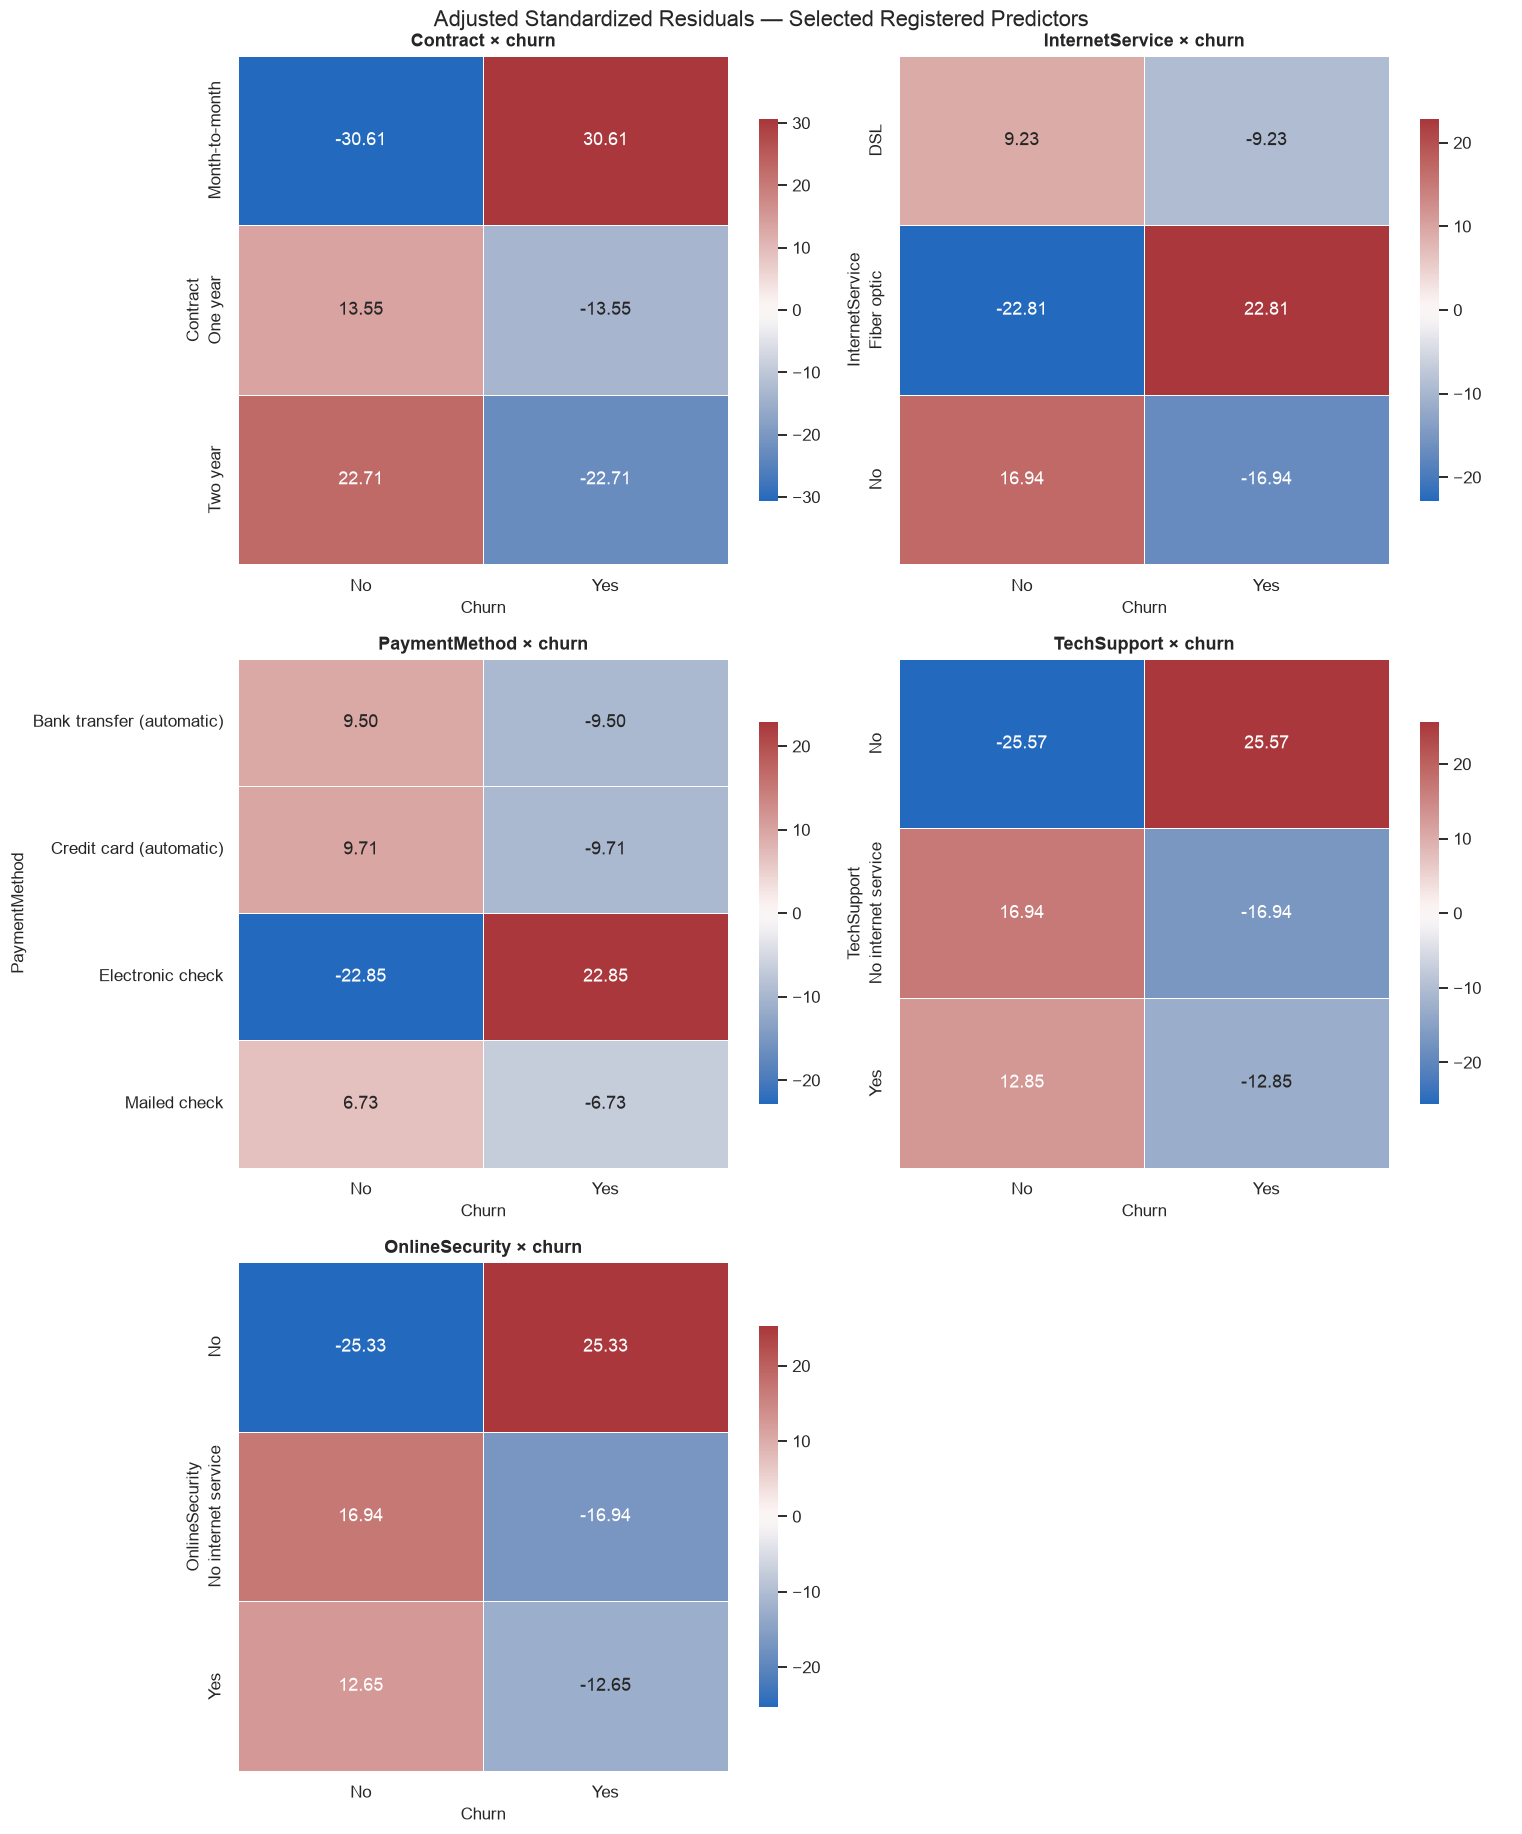

In [5]:
# ruff: noqa: E501
notebook_05_reference_v = {"Contract": 0.412, "TechSupport": 0.345, "OnlineSecurity": 0.342, "InternetService": 0.318, "PaymentMethod": 0.305}
v_consistency = chi_square_results[chi_square_results["predictor"].isin(notebook_05_reference_v)].copy()
v_consistency["notebook_05_rounded_reference"] = v_consistency["predictor"].map(notebook_05_reference_v)
v_consistency["current_rounded_3dp"] = v_consistency["bias_corrected_cramers_v"].round(3)
v_consistency["matches_notebook_05"] = v_consistency["current_rounded_3dp"].eq(v_consistency["notebook_05_rounded_reference"])
display(v_consistency[["predictor", "bias_corrected_cramers_v", "manual_v_check", "notebook_05_rounded_reference", "matches_notebook_05"]])

selected_residual_predictors = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"]
fig, axes = plt.subplots(3, 2, figsize=(14, 17))
for axis, predictor in zip(axes.flat, selected_residual_predictors, strict=False):
    sns.heatmap(residual_tables[predictor], annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=0.5, cbar_kws={"shrink": 0.75}, ax=axis)
    axis.set(title=f"{predictor} × churn", xlabel="Churn", ylabel=predictor)
axes.flat[-1].axis("off")
fig.suptitle("Adjusted Standardized Residuals — Selected Registered Predictors")
fig.tight_layout()
plt.show()

## 6. Consolidated exploratory results

Small p-values are retained numerically and formatted in scientific notation. Association
strength and statistical detection are reported separately. No multiplicity correction is
performed yet.

In [6]:
# ruff: noqa: E501
business_interpretations = {
    "Contract": "Commitment level has the strongest registered categorical association; month-to-month contributes excess churn while longer contracts contribute fewer churn observations than independence predicts.",
    "InternetService": "Fibre optic contributes excess churn and DSL/no-internet contribute fewer churn observations; product mix, price, and experience may confound the marginal association.",
    "PaymentMethod": "Electronic check contributes excess churn while automatic methods contribute fewer churn observations; this is association, not proof of payment friction causing churn.",
    "TechSupport": "No technical support contributes excess churn, while support adoption and the structural no-internet state contribute fewer churn observations.",
    "OnlineSecurity": "No online security contributes excess churn, while adoption and the structural no-internet state contribute fewer churn observations.",
    "PaperlessBilling": "Paperless billing is associated with churn, but channel, payment method, contract, and customer mix may explain part of the marginal pattern.",
    "gender": "The development sample does not provide a raw-p-value basis to reject independence for gender; this does not establish fairness or irrelevance.",
    "SeniorCitizen": "Senior-citizen status is associated with churn; use as a fairness-monitoring signal, not discriminatory targeting.",
    "Partner": "Partner status is associated with churn but may proxy lifecycle and household structure.",
    "Dependents": "Dependent status is associated with churn but may proxy lifecycle and household structure.",
}


def format_p(value):
    if value == 0:
        return f"underflow (<{np.nextafter(0, 1):.2e})"
    return f"{value:.6e}"


consolidated_results = chi_square_results.copy()
consolidated_results["raw_p_value_display"] = consolidated_results["raw_p_value"].map(format_p)
consolidated_results["business_interpretation"] = consolidated_results["predictor"].map(business_interpretations)
consolidated_results = consolidated_results[["hypothesis_id", "predictor", "test", "sample_size", "chi_square", "degrees_of_freedom", "raw_p_value", "raw_p_value_display", "minimum_expected_frequency", "cells_expected_below_5", "expected_frequency_assumption_met", "bias_corrected_cramers_v", "preliminary_decision", "business_interpretation", "hypothesis_family", "multiplicity_status"]]
display(consolidated_results)

display(Markdown(
    "### Actual-result summary\n\n"
    + "\n".join(
        f"- **{row.hypothesis_id} — {row.predictor}:** χ²({int(row.degrees_of_freedom)})={row.chi_square:.3f}, raw p={row.raw_p_value_display}, corrected V={row.bias_corrected_cramers_v:.3f}; minimum expected={row.minimum_expected_frequency:.2f}; {row.preliminary_decision}."
        for _, row in consolidated_results.iterrows()
    )
))

,hypothesis_id,predictor,test,sample_size,chi_square,degrees_of_freedom,raw_p_value,raw_p_value_display,minimum_expected_frequency,cells_expected_below_5,expected_frequency_assumption_met,bias_corrected_cramers_v,preliminary_decision,business_interpretation,hypothesis_family,multiplicity_status
0,HYP-04,Contract,Pearson chi-square (no continuity correction),5634,958.56217,2,7.0936511e-209,7.093651e-209,312.58608,0,True,0.41208485,Reject independence (exploratory),Commitment level has the strongest registered ...,Categorical predictors versus churn,Raw/unadjusted; correction deferred
1,HYP-05,InternetService,Pearson chi-square (no continuity correction),5634,571.3832,2,8.4278168e-125,8.427817e-125,320.28133,0,True,0.31793059,Reject independence (exploratory),Fibre optic contributes excess churn and DSL/n...,Categorical predictors versus churn,Raw/unadjusted; correction deferred
2,HYP-06,PaymentMethod,Pearson chi-square (no continuity correction),5634,527.34699,3,5.6476113e-114,5.647611e-114,322.40415,0,True,0.30509796,Reject independence (exploratory),Electronic check contributes excess churn whil...,Categorical predictors versus churn,Raw/unadjusted; correction deferred
3,HYP-07,TechSupport,Pearson chi-square (no continuity correction),5634,672.94037,2,7.4619955e-147,7.461996e-147,320.28133,0,True,0.34512147,Reject independence (exploratory),"No technical support contributes excess churn,...",Categorical predictors versus churn,Raw/unadjusted; correction deferred
4,HYP-08,OnlineSecurity,Pearson chi-square (no continuity correction),5634,660.68196,2,3.4255961e-144,3.425596e-144,320.28133,0,True,0.34195416,Reject independence (exploratory),"No online security contributes excess churn, w...",Categorical predictors versus churn,Raw/unadjusted; correction deferred
5,HYP-09,PaperlessBilling,Pearson chi-square (no continuity correction),5634,209.19413,1,2.059134e-47,2.059134e-47,602.08644,0,True,0.19224904,Reject independence (exploratory),"Paperless billing is associated with churn, bu...",Categorical predictors versus churn,Raw/unadjusted; correction deferred
6,HYP-10a,gender,Pearson chi-square (no continuity correction),5634,1.3768402,1,0.24064011,2.406401e-01,735.55911,0,True,0.0081772342,Do not reject independence,The development sample does not provide a raw-...,Demographic characteristics versus churn,Raw/unadjusted; correction deferred
7,HYP-10b,SeniorCitizen,Pearson chi-square (no continuity correction),5634,132.11683,1,1.4106815e-30,1.410682e-30,240.94072,0,True,0.15256646,Reject independence (exploratory),Senior-citizen status is associated with churn...,Demographic characteristics versus churn,Raw/unadjusted; correction deferred
8,HYP-10c,Partner,Pearson chi-square (no continuity correction),5634,130.22232,1,3.6635862e-30,3.663586e-30,715.92297,0,True,0.15146023,Reject independence (exploratory),Partner status is associated with churn but ma...,Demographic characteristics versus churn,Raw/unadjusted; correction deferred
9,HYP-10d,Dependents,Pearson chi-square (no continuity correction),5634,140.72284,1,1.8498961e-32,1.849896e-32,453.75399,0,True,0.15749384,Reject independence (exploratory),Dependent status is associated with churn but ...,Demographic characteristics versus churn,Raw/unadjusted; correction deferred


### Actual-result summary

- **HYP-04 — Contract:** χ²(2)=958.562, raw p=7.093651e-209, corrected V=0.412; minimum expected=312.59; Reject independence (exploratory).
- **HYP-05 — InternetService:** χ²(2)=571.383, raw p=8.427817e-125, corrected V=0.318; minimum expected=320.28; Reject independence (exploratory).
- **HYP-06 — PaymentMethod:** χ²(3)=527.347, raw p=5.647611e-114, corrected V=0.305; minimum expected=322.40; Reject independence (exploratory).
- **HYP-07 — TechSupport:** χ²(2)=672.940, raw p=7.461996e-147, corrected V=0.345; minimum expected=320.28; Reject independence (exploratory).
- **HYP-08 — OnlineSecurity:** χ²(2)=660.682, raw p=3.425596e-144, corrected V=0.342; minimum expected=320.28; Reject independence (exploratory).
- **HYP-09 — PaperlessBilling:** χ²(1)=209.194, raw p=2.059134e-47, corrected V=0.192; minimum expected=602.09; Reject independence (exploratory).
- **HYP-10a — gender:** χ²(1)=1.377, raw p=2.406401e-01, corrected V=0.008; minimum expected=735.56; Do not reject independence.
- **HYP-10b — SeniorCitizen:** χ²(1)=132.117, raw p=1.410682e-30, corrected V=0.153; minimum expected=240.94; Reject independence (exploratory).
- **HYP-10c — Partner:** χ²(1)=130.222, raw p=3.663586e-30, corrected V=0.151; minimum expected=715.92; Reject independence (exploratory).
- **HYP-10d — Dependents:** χ²(1)=140.723, raw p=1.849896e-32, corrected V=0.157; minimum expected=453.75; Reject independence (exploratory).

In [7]:
# ruff: noqa: E501
def strongest_residuals(predictor, limit=4):
    view = contingency_diagnostics[contingency_diagnostics["predictor"].eq(predictor)].copy()
    return view.reindex(view["adjusted_standardized_residual"].abs().sort_values(ascending=False).index).head(limit)


key_residual_patterns = pd.concat([strongest_residuals(predictor) for predictor in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]], ignore_index=True)
display(key_residual_patterns)

,hypothesis_id,predictor,category,churn_outcome,observed_frequency,expected_frequency,adjusted_standardized_residual
0,HYP-04,Contract,Month-to-month,Yes,1326,821.26819,30.60948
1,HYP-04,Contract,Month-to-month,No,1769,"2,273.7318",-30.60948
2,HYP-04,Contract,Two year,Yes,39,361.14572,-22.709826
3,HYP-04,Contract,Two year,No,1322,999.85428,22.709826
4,HYP-05,InternetService,Fiber optic,No,1456,"1,831.4744",-22.81089
5,HYP-05,InternetService,Fiber optic,Yes,1037,661.52556,22.81089
6,HYP-05,InternetService,No,Yes,90,320.28133,-16.935861
7,HYP-05,InternetService,No,No,1117,886.71867,16.935861
8,HYP-06,PaymentMethod,Electronic check,No,1022,"1,378.932",-22.850186
9,HYP-06,PaymentMethod,Electronic check,Yes,855,498.06798,22.850186


## 7. Business, fairness, and machine-learning implications

Contract has the largest corrected V, followed by support/security, internet service, and
payment method. The residual heatmaps show which cells create those unsigned associations:
month-to-month, fibre optic, electronic check, and absent support/security have excess churn
relative to independence; longer commitment, automatic payments, and service adoption tend
in the opposite direction. Structural `No internet service` states are preserved and should
not be treated as missing.

Statistical significance is not effect magnitude, predictive usefulness, or causation.
Cramér's V is marginal; correlated service, price, tenure, and contract variables can share
information. A predictor with a detectable association may add no incremental out-of-sample
value, and no feature is removed or selected here.

Demographic findings require fairness review: monitor subgroup performance, access,
calibration, and adverse impact. They are not a justification for discriminatory targeting.
Gender's non-rejection is not proof of independence or fairness; senior/household
associations may reflect confounding and population composition.

## 8. Interview questions with speakable answers

### Q1. How does the chi-square test of independence work?

**Answer:** It compares each observed contingency-table count with the count expected if row
and column variables were independent. Squared deviations divided by expected counts are
summed into chi-square and compared with a chi-square distribution using
$(r-1)(c-1)$ degrees of freedom. It needs independent observations and adequate expected
counts. Rejection indicates association, not strength or causation.

### Q2. When should Fisher's exact test be preferred?

**Answer:** For a suitable 2×2 table with small or inadequate expected counts, Fisher gives
an exact conditional p-value instead of relying on a chi-square approximation. It is not a
reason to collapse meaningful multicategory predictors. Here all registered 2×2 tables meet
the expected-count diagnostic, so Fisher is unnecessary.

### Q3. Chi-square significance versus Cramér's V?

**Answer:** The chi-square p-value measures evidence against independence and becomes highly
sensitive with large samples. Cramér's V standardizes association magnitude from zero to
one. V is unsigned, so it cannot say which category has more churn. I report both, then use
residuals for cell direction.

### Q4. How do standardized residuals help?

**Answer:** They show which cells have more or fewer observations than independence predicts
after accounting for row and column margins. Positive means excess, negative means deficit,
and large absolute values identify major contributors. Because many cells are screened,
residual interpretation is exploratory and has its own multiplicity risk.

## 9. Assumptions and limitations

1. Rows are treated as independent customers; unrecorded household, account, geographic,
   or temporal clustering could invalidate reference distributions.
2. The sampling mechanism and target population are unknown; significance does not repair
   selection bias.
3. Expected-count checks support the chi-square approximation in this sample but do not
   establish independence or representativeness.
4. Raw tests and residual screens are unadjusted; family-wise correction is deferred.
5. Corrected V is unsigned and marginal; residual signs depend on observed cell coding.
6. Structural service states and confounding require domain-aware interpretation.
7. No causality, feature selection, engineering, balancing, preprocessing, modelling,
   ANOVA, multiple-group comparison, or categorical multiplicity correction is performed.

## 10. Numerical, integrity, and leakage verification

The final cell checks expected-frequency calculations, SciPy/manual chi-square agreement,
package/manual corrected V agreement, residual identities, Fisher eligibility, all eleven
prior notebook hashes, source checksum, and development-only loading.

In [8]:
# ruff: noqa: E501
for _, row in chi_square_results.iterrows():
    predictor = row["predictor"]
    observed = contingency_tables[predictor].to_numpy(float)
    expected = expected_tables[predictor].to_numpy(float)
    assert np.all(expected > 0)
    assert np.allclose(expected.sum(axis=0), observed.sum(axis=0))
    assert np.allclose(expected.sum(axis=1), observed.sum(axis=1))
    manual_chi_square = np.sum((observed - expected) ** 2 / expected)
    assert np.isclose(manual_chi_square, row["chi_square"], rtol=1e-12)
    assert np.isclose(row["bias_corrected_cramers_v"], row["manual_v_check"], rtol=1e-12)
    assert np.isfinite(residual_tables[predictor].to_numpy()).all()

assert v_consistency["matches_notebook_05"].all()
assert chi_square_results["expected_frequency_assumption_met"].all()
assert not fisher_decisions["fisher_exact_needed"].any()
assert chi_square_results["raw_p_value"].between(0, 1).all()
assert chi_square_results["bias_corrected_cramers_v"].between(0, 1).all()
assert list(categorical_hypotheses) == ["HYP-04", "HYP-05", "HYP-06", "HYP-07", "HYP-08", "HYP-09", "HYP-10a", "HYP-10b", "HYP-10c", "HYP-10d"]

expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
    "07_customer_segmentation_business_analysis.ipynb": "1dee5509dc803187d99bb61af9d2eefc272f8a83c9d1014409f35834ca35cf6d",
    "08_statistical_foundations.ipynb": "11578c2e7cfa07a3fb826601d7afb356c224443d6547f7dc93725b45ac6653f2",
    "09_confidence_interval_analysis.ipynb": "50bf2497adec4d4e5d09502b0849420c9e53d5383615152f51fbc71629fb61c3",
    "10_distribution_diagnostics.ipynb": "38341766a6a26f1c7ba03c521500d15eef0038efd9e01d7b6bf7468de0dd1b58",
    "11_numerical_hypothesis_testing.ipynb": "fe98c6d2591d9f87dd256ae9a37a32004e194297f8dc01ce44abc6bff6501662",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

assert observed_previous_hashes == expected_previous_hashes
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert development_path != (PROJECT_ROOT / config["data"]["test_path"]).resolve()
assert development_path != (PROJECT_ROOT / config["data"]["validated_path"]).resolve()
assert random_state == 42 and alpha == 0.05

print("All categorical-test, residual, effect-size, integrity, and leakage checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All categorical-test, residual, effect-size, integrity, and leakage checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...
07_customer_segmentation_business_analysis.ipynb,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...
08_statistical_foundations.ipynb,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...
09_confidence_interval_analysis.ipynb,50bf2497adec4d4e5d09502b0849420c9e53d538361515...,50bf2497adec4d4e5d09502b0849420c9e53d538361515...
10_distribution_diagnostics.ipynb,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...
